# 04 Analysis

**Input:** `data/processed/jobs_extracted.pkl` from `03_extraction`, with one row per ad (1,062 data-role ads), plus three groups of skill columns:
`skill_` (mentioned at all), `req_` (mentioned as required) and `nice_` (only nice-to-have).

**Questions**
1. Which skills are required, and which are only nice to have?
2. How open are ads to newcomers (experience, degree, German)?
3. How do expectations differ between roles, and between junior and senior ads?

**Methods**
- Shares with **95% Wilson confidence intervals**. Wilson is more accurate than the normal approximation for small groups and for shares near 0 or 1.
- **Log-odds ratios** (role vs. all other ads, +0.5 smoothing), to find skills that are *typical* of a role rather than just frequent everywhere
- **Fisher's exact test** for junior vs. senior, because the junior group is small. Differences are reported in percentage points, and p-values are adjusted for multiple testing (Benjamini–Hochberg).
- **Ad language** (from `03_extraction`), to separate German-language ads, which usually expect German without saying so, from English-language ads
- **Robustness checks:** shares weighted by duplicate copies, without ads older than one year, and with every employer weighted equally

**Output:** figures in `reports/figures/` and aggregated tables for the Streamlit app in `app/data/` (no ad texts).

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, false_discovery_control, fisher_exact, spearmanr

PROCESSED_DIR = Path.cwd().parent / "data" / "processed"
FIG_DIR = Path.cwd().parent / "reports" / "figures"
APP_DIR = Path.cwd().parent / "app" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
APP_DIR.mkdir(parents=True, exist_ok=True)

# Muted style, same as in 03_extraction
MAIN, GREY, DARK = "#5b7a99", "#c9ced6", "#2f3e4e"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

jobs = pd.read_pickle(PROCESSED_DIR / "jobs_extracted.pkl")
SKILLS = [c.removeprefix("skill_") for c in jobs.columns if c.startswith("skill_")]

def skill_frame(prefix):
    """True/False matrix ads x skills for one prefix, with plain skill names as columns."""
    return jobs[[prefix + s for s in SKILLS]].set_axis(SKILLS, axis=1)

S, REQ, NICE = skill_frame("skill_"), skill_frame("req_"), skill_frame("nice_")
N = len(jobs)
print(f"{N} ads, {len(SKILLS)} skills")
print(jobs["role"].value_counts(), "\n")
print(jobs["seniority"].value_counts())

1062 ads, 46 skills
role
Data Engineer       281
Data Analyst        247
ML / AI Engineer    211
BI / Analytics      119
Data Scientist      119
Other data role      85
Name: count, dtype: int64 

seniority
not stated    757
senior        250
junior         55
Name: count, dtype: int64


In [2]:
def wilson(k, n):
    """Share k/n with its 95% Wilson confidence interval: (share, low, high)."""
    if n == 0:
        return np.nan, np.nan, np.nan
    ci = binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
    return k / n, ci.low, ci.high

def share_ci(mask):
    """Share of True values in a boolean Series, with Wilson interval."""
    return wilson(mask.sum(), len(mask))

def ci_table(df):
    """One row per column of a boolean DataFrame: share, low, high."""
    return pd.DataFrame({c: share_ci(df[c]) for c in df}, index=["share", "low", "high"]).T

def errbars(t):
    """Distances from the share to the interval bounds, as matplotlib expects them."""
    return [t["share"] - t["low"], t["high"] - t["share"]]

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    print("saved", name)

## 2. How often is each skill mentioned?

Share of the 1,062 ads that mention a skill anywhere in the text, with 95% confidence intervals. Overlapping intervals mean the difference between two skills is not reliable.

                  share   low  high
Python             45.9  42.9  48.9
SQL                43.6  40.6  46.6
Machine learning   29.9  27.3  32.8
Data modelling     29.8  27.1  32.6
Power BI           20.7  18.4  23.3
Azure              20.2  17.9  22.8
ETL / ELT          20.2  17.9  22.8
Data warehouse     18.9  16.7  21.4
SAP                18.1  15.9  20.5
Statistics         16.9  14.8  19.3
LLM / GenAI        14.2  12.2  16.4
AWS                13.4  11.5  15.6
Excel              11.0   9.3  13.0
Git                10.7   9.0  12.7
Databricks          9.2   7.6  11.1
saved skills_ci.png


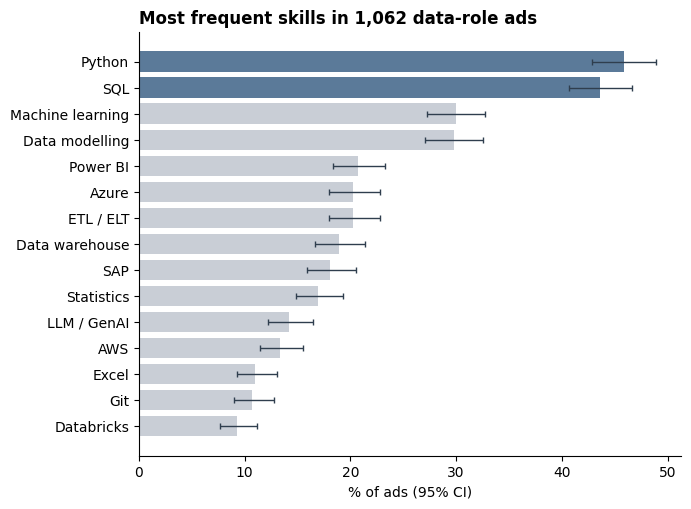

In [3]:
shares = ci_table(S).sort_values("share", ascending=False)
TOP = shares.index[:15].tolist()           # the 15 most frequent skills, used throughout
print((shares.head(15) * 100).round(1).to_string())

t = shares.loc[TOP][::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(t.index, t["share"] * 100, xerr=[e * 100 for e in errbars(t)],
        color=[GREY] * 13 + [MAIN] * 2, error_kw={"ecolor": DARK, "elinewidth": 1, "capsize": 2})
ax.set_xlabel("% of ads (95% CI)")
ax.set_title(f"Most frequent skills in {N:,} data-role ads")
save(fig, "skills_ci.png")
plt.show()

## 3. Required or nice-to-have?

For each skill, the share of ads that list it as **required** and the share that list it **only as nice-to-have**. The share nice-to-have is calculated among the ads that mention the skill, with a confidence interval. The few mentions that could not be assigned to a unit (pattern split across a unit boundary) are in neither group.

                  mentioned  required  nice  share nice   low  high
Python                  487       404    83        0.17  0.14  0.21
SQL                     463       391    72        0.16  0.13  0.19
Machine learning        318       299    19        0.06  0.04  0.09
Data modelling          316       295    21        0.07  0.04  0.10
Power BI                220       182    38        0.17  0.13  0.23
Azure                   215       175    40        0.19  0.14  0.24
ETL / ELT               215       199    16        0.07  0.05  0.12
Data warehouse          201       178    23        0.11  0.08  0.17
SAP                     192       167    25        0.13  0.09  0.19
Statistics              180       164    16        0.09  0.06  0.14
LLM / GenAI             151       147     4        0.03  0.01  0.07
AWS                     142       115    27        0.19  0.13  0.26
Excel                   117        98    19        0.16  0.11  0.24
Git                     114        91    23     

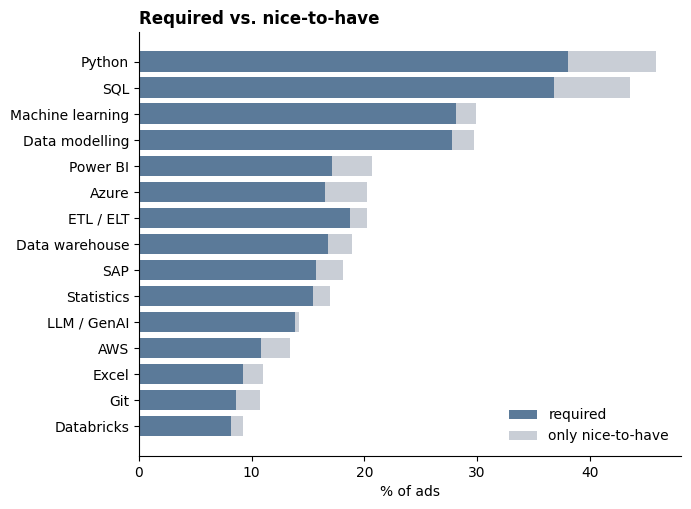

In [4]:
req_nice = pd.DataFrame({"mentioned": S.sum(), "required": REQ.sum(), "nice": NICE.sum()})
nice_ci = pd.DataFrame({s: wilson(req_nice.at[s, "nice"], req_nice.at[s, "mentioned"]) for s in SKILLS},
                       index=["share nice", "low", "high"]).T
req_nice = req_nice.join(nice_ci)
print(req_nice.loc[TOP].round(2).to_string())

t = req_nice.loc[TOP][::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(t.index, t["required"] / N * 100, color=MAIN, label="required")
ax.barh(t.index, t["nice"] / N * 100, left=t["required"] / N * 100, color=GREY, label="only nice-to-have")
ax.set_xlabel("% of ads")
ax.set_title("Required vs. nice-to-have")
ax.legend(frameon=False, loc="lower right")
save(fig, "required_vs_nice.png")
plt.show()

In [5]:
# Skills most often only nice-to-have (at least 30 ads mention them)
frequent = req_nice[req_nice["mentioned"] >= 30]
print(frequent.sort_values("share nice", ascending=False)
      [["mentioned", "nice", "share nice", "low", "high"]].head(10).round(2).to_string())

                   mentioned  nice  share nice   low  high
Kafka                     41    11        0.27  0.16  0.42
Airflow                   60    16        0.27  0.17  0.39
R                         92    23        0.25  0.17  0.35
Linux                     54    13        0.24  0.15  0.37
DAX / Power Query         47    11        0.23  0.14  0.37
Terraform                 33     7        0.21  0.11  0.38
Java                      66    14        0.21  0.13  0.33
Tableau                   52    11        0.21  0.12  0.34
Git                      114    23        0.20  0.14  0.28
Spark                     83    16        0.19  0.12  0.29


## 4. What distinguishes the roles?

The first cell lists the **five most typical skills of each role**, measured by the log-odds ratio of the role against all other ads. Only skills that at least 10 ads of the role mention are considered. The +0.5 smoothing avoids division by zero for rare skills. "Other data role" is not shown as a role, but it is part of "all other ads".

The heatmap then shows the 10 most frequent skills plus the 3 most typical skills of each role, ordered so that each role's typical skills form a block. The **number** in a cell is the share of the role's ads that mention the skill; the **colour** is the log-odds ratio:
- blue: the skill is more typical of this role than of the others
- red: it is less typical
- white: no difference

The colours describe differences; they are not significance tests.

In [6]:
ROLE_ORDER = ["Data Analyst", "BI / Analytics", "Data Scientist", "Data Engineer", "ML / AI Engineer"]

def log_odds(skill, in_role):
    """Log-odds ratio of mentioning a skill: role vs. all other ads (+0.5 smoothing)."""
    a = (skill & in_role).sum() + 0.5
    b = (~skill & in_role).sum() + 0.5
    c = (skill & ~in_role).sum() + 0.5
    d = (~skill & ~in_role).sum() + 0.5
    return np.log((a / b) / (c / d))

# Log-odds, share and number of ads for every skill (rows) and role (columns)
role_lor = pd.DataFrame({r: {s: log_odds(S[s], jobs["role"] == r) for s in SKILLS} for r in ROLE_ORDER})
role_share = S.groupby(jobs["role"]).mean().T
role_count = S.groupby(jobs["role"]).sum().T

# The five most typical skills per role (each mentioned in at least 10 ads of the role)
typical = {r: role_lor[r][role_count[r] >= 10].sort_values(ascending=False).head(5).index.tolist()
           for r in ROLE_ORDER}
for r, skills in typical.items():
    print(f"{r:18}", ", ".join(f"{s} ({role_share.at[s, r]:.0%})" for s in skills))

Data Analyst       Excel (31%), Tableau (10%), Power BI (35%), R (14%), Statistics (24%)
BI / Analytics     Qlik (17%), DAX / Power Query (17%), SAP (43%), Power BI (42%), Data modelling (54%)
Data Scientist     Statistics (64%), scikit-learn (14%), Machine learning (67%), pandas (9%), Python (76%)
Data Engineer      Kafka (12%), Airflow (17%), dbt (17%), Spark (21%), ETL / ELT (48%)
ML / AI Engineer   TensorFlow (18%), LLM / GenAI (48%), PyTorch (24%), Deep learning (17%), Machine learning (70%)


saved role_heatmap.png


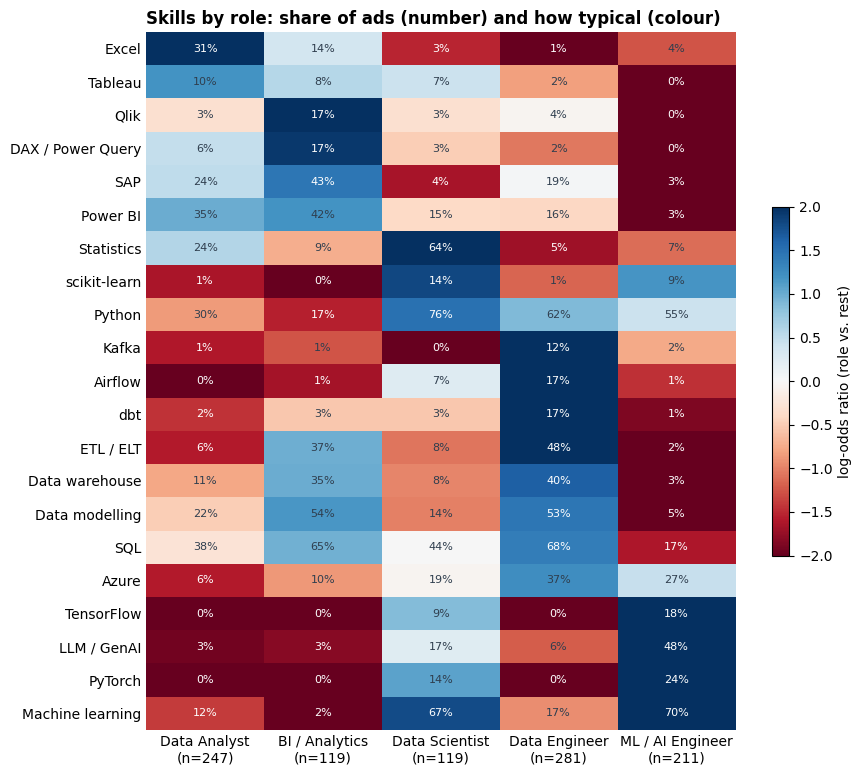

In [7]:
# Heatmap rows: the 10 most frequent skills plus the 3 most typical skills of each role,
# ordered by the role they are most typical of, so each role's skills form a block
HEAT = list(dict.fromkeys(TOP[:10] + [s for r in ROLE_ORDER for s in typical[r][:3]]))
HEAT = sorted(HEAT, key=lambda s: (ROLE_ORDER.index(role_lor.loc[s].idxmax()), -role_lor.loc[s].max()))
lor, share = role_lor.loc[HEAT, ROLE_ORDER], role_share.loc[HEAT, ROLE_ORDER]

fig, ax = plt.subplots(figsize=(9.5, 0.36 * len(HEAT) + 1.5))
im = ax.imshow(lor.values, cmap="RdBu", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(ROLE_ORDER)), [f"{r}\n(n={(jobs['role'] == r).sum()})" for r in ROLE_ORDER])
ax.set_yticks(range(len(HEAT)), HEAT)
for i in range(len(HEAT)):
    for j in range(len(ROLE_ORDER)):
        ax.text(j, i, f"{share.iat[i, j] * 100:.0f}%", ha="center", va="center", fontsize=8,
                color="white" if abs(lor.iat[i, j]) > 1.3 else DARK)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=0.5, label="log-odds ratio (role vs. rest)")
ax.set_title("Skills by role: share of ads (number) and how typical (colour)")
save(fig, "role_heatmap.png")
plt.show()

## 5. Junior vs. senior

Only 55 titles say *junior*, so differences need a careful test. **Fisher's exact test** compares junior and senior ads for each requirement. The table gives the **difference in percentage points** (junior minus senior) as the effect size. Because eight requirements are tested at once, the p-values are adjusted with Benjamini–Hochberg. Ads without a level in the title are shown for reference, but not tested.

In [8]:
# "Fluent or higher": the step above "gut / sehr gut" in the common German CV scale (see section 7)
HIGH_GERMAN = ["CEFR C1/C2", "fluent / native"]
MEASURES = {
    "entry signal in text":           jobs["entry_signal"],
    "3+ or several years required":   jobs["exp_level"].isin(["3-4", "5+", "several years (no number)"]),
    "5+ years required":              jobs["exp_level"] == "5+",
    "degree mentioned":               jobs["degree"],
    "alternative to degree":          jobs["alt_path"],
    "PhD mentioned":                  jobs["phd"],
    "German: fluent or higher":       jobs["german"].isin(HIGH_GERMAN),
    "German not mentioned":           jobs["german"] == "not mentioned",
}
LEVELS = ["junior", "senior", "not stated"]

rows = []
for name, m in MEASURES.items():
    row = {"measure": name}
    for lvl in LEVELS:
        g = m[jobs["seniority"] == lvl]
        row[lvl], row[f"{lvl} low"], row[f"{lvl} high"] = share_ci(g)
    j, s = m[jobs["seniority"] == "junior"], m[jobs["seniority"] == "senior"]
    row["difference (pp)"] = (j.mean() - s.mean()) * 100        # effect size: junior minus senior
    row["p"] = fisher_exact([[j.sum(), (~j).sum()], [s.sum(), (~s).sum()]])[1]
    rows.append(row)
js = pd.DataFrame(rows).set_index("measure")
js["p adjusted"] = false_discovery_control(js["p"], method="bh")

print("ads per level:", {lvl: int((jobs["seniority"] == lvl).sum()) for lvl in LEVELS}, "\n")
print((js[LEVELS] * 100).round(1)
      .join(js[["difference (pp)"]].round(1))
      .join(js[["p", "p adjusted"]].round(4)).to_string())

ads per level: {'junior': 55, 'senior': 250, 'not stated': 757} 

                              junior  senior  not stated  difference (pp)       p  p adjusted
measure                                                                                      
entry signal in text            49.1     4.0        15.3             45.1  0.0000      0.0000
3+ or several years required     3.6    62.8        31.4            -59.2  0.0000      0.0000
5+ years required                0.0    17.6         3.2            -17.6  0.0002      0.0004
degree mentioned                81.8    68.0        80.1             13.8  0.0497      0.0994
alternative to degree           20.0    27.6        34.1             -7.6  0.3101      0.3544
PhD mentioned                    1.8     8.8         5.9             -7.0  0.0916      0.1466
German: fluent or higher        14.5    21.6        23.0             -7.1  0.2720      0.3544
German not mentioned            45.5    47.6        46.0             -2.1  0.8816      0

saved junior_vs_senior.png


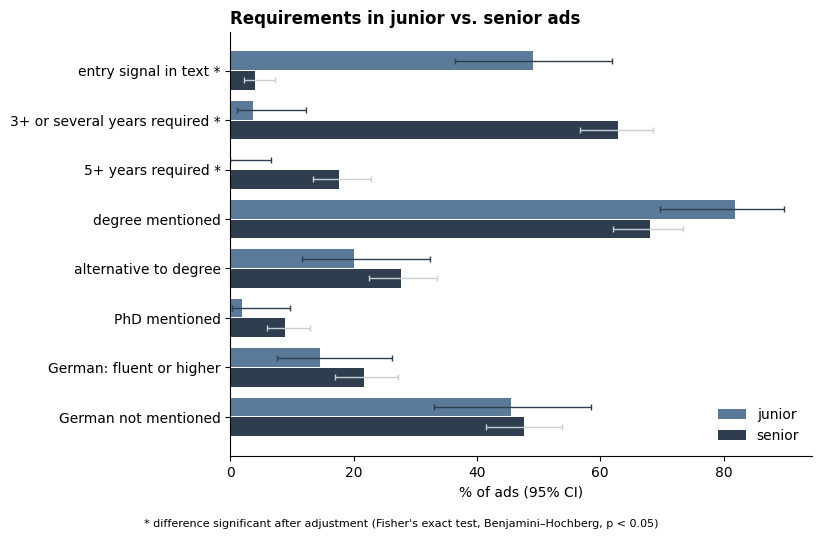

In [9]:
t = js[::-1]
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for k, (lvl, color) in enumerate([("junior", MAIN), ("senior", DARK)]):
    sub = t[[lvl, f"{lvl} low", f"{lvl} high"]].set_axis(["share", "low", "high"], axis=1)
    ax.barh(y + (0.2 if k == 0 else -0.2), sub["share"] * 100, height=0.38, color=color, label=lvl,
            xerr=[e * 100 for e in errbars(sub)], error_kw={"ecolor": GREY if k else DARK, "elinewidth": 1, "capsize": 2})
ax.set_yticks(y, [f"{m}{' *' if p < 0.05 else ''}" for m, p in zip(t.index, t["p adjusted"])])
ax.set_xlabel("% of ads (95% CI)")
ax.set_title("Requirements in junior vs. senior ads")
ax.legend(frameon=False, loc="lower right")
fig.text(0.01, -0.02, "* difference significant after adjustment (Fisher's exact test, Benjamini–Hochberg, p < 0.05)", fontsize=8)
save(fig, "junior_vs_senior.png")
plt.show()

**Check: is the entry signal partly built into the junior definition?** Some words count both for a junior title and as an entry signal in the text ("Einsteiger", "Absolvent", "Graduate", "Trainee", "Entry"). If an ad repeats its title in the text, the entry signal follows from the title. The cell compares junior ads with such a word in the title to junior ads without one (e.g. a plain "Junior Data Analyst").

In [10]:
ENTRY_TITLE_WORDS = r"(?i)einsteig|absolvent|graduate|trainee|entry"
junior = jobs["seniority"] == "junior"
title_overlap = jobs["stellenangebotsTitel"].str.contains(ENTRY_TITLE_WORDS)

for name, m in [("junior, entry word in title", junior & title_overlap),
                ("junior, no entry word in title", junior & ~title_overlap)]:
    share, low, high = share_ci(jobs.loc[m, "entry_signal"])
    print(f"{name:32} n = {m.sum():>3}   entry signal in text: {share:.1%} (CI {low:.1%}–{high:.1%})")

junior, entry word in title      n =   8   entry signal in text: 50.0% (CI 21.5%–78.5%)
junior, no entry word in title   n =  47   entry signal in text: 48.9% (CI 35.3%–62.8%)


## 6. Which roles are open to newcomers?

An ad counts as **newcomer-friendly** if at least one of these holds:
- the title says *junior*
- the text contains an entry signal ("Berufseinsteiger", "erste Erfahrung", …)
- it asks for at most 1–2 years of experience

The table also shows the share of ads that do **not mention German**. Section 7 looks at what that means.

all ads: 21.3% newcomer-friendly, 46.3% do not mention German

                  newcomer   low  high  no German      n
BI / Analytics        15.1   9.8  22.6       44.5  119.0
ML / AI Engineer      17.5  13.0  23.2       46.0  211.0
Data Engineer         18.9  14.7  23.8       38.8  281.0
Data Scientist        20.2  13.9  28.3       42.0  119.0
Other data role       21.2  13.8  31.0       67.1   85.0
Data Analyst          30.8  25.3  36.8       51.0  247.0
saved newcomer_by_role.png


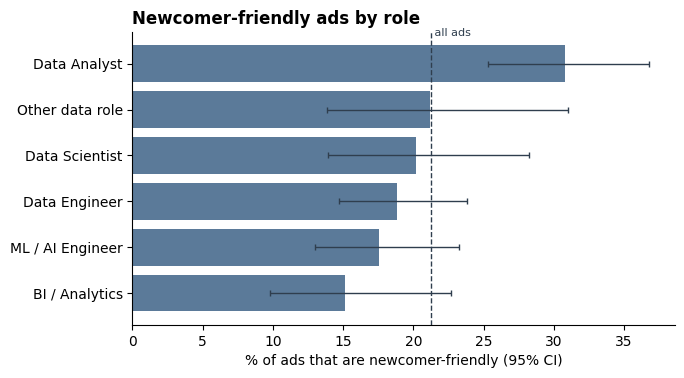

In [11]:
newcomer = ((jobs["seniority"] == "junior") | jobs["entry_signal"] | (jobs["exp_level"] == "1-2")).rename("newcomer-friendly")
no_german = (jobs["german"] == "not mentioned").rename("German not mentioned")

by_role = pd.DataFrame({r: {**dict(zip(["newcomer", "low", "high"], share_ci(newcomer[jobs["role"] == r]))),
                            "no German": no_german[jobs["role"] == r].mean(),
                            "n": int((jobs["role"] == r).sum())}
                        for r in ROLE_ORDER + ["Other data role"]}).T
by_role = by_role.sort_values("newcomer")
print(f"all ads: {newcomer.mean():.1%} newcomer-friendly, {no_german.mean():.1%} do not mention German\n")
print(by_role.assign(**{c: (by_role[c] * 100).round(1) for c in ["newcomer", "low", "high", "no German"]}).to_string())

t = by_role.astype(float)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(t.index, t["newcomer"] * 100, xerr=[e * 100 for e in errbars(t.rename(columns={"newcomer": "share"}))],
        color=MAIN, error_kw={"ecolor": DARK, "elinewidth": 1, "capsize": 2})
ax.axvline(newcomer.mean() * 100, color=DARK, lw=1, ls="--")
ax.text(newcomer.mean() * 100, len(t) - 0.4, " all ads", fontsize=8, color=DARK)
ax.set_xlabel("% of ads that are newcomer-friendly (95% CI)")
ax.set_title("Newcomer-friendly ads by role")
save(fig, "newcomer_by_role.png")
plt.show()

## 7. German: does the language of the ad matter?

An ad that does not mention German is not necessarily open to non-German speakers: an ad **written in German** usually expects German without saying so. The language of each ad comes from `03_extraction` (share of German vs. English function words, checked by hand). German requirements are grouped into three levels:
- *fluent or higher*: fließend, verhandlungssicher, muttersprachlich, C1/C2
- *mentioned, lower or no level*: gut, sehr gut, sicher, B1/B2, Grundkenntnisse, no level
- *not mentioned*

**Why the cut is at "fließend":** in the scale commonly used in German CVs, "gute" and "sehr gute Kenntnisse" form one level, and "fließend" is the next step up ([bewerbung.net](https://bewerbung.net/sprachkenntnisse-lebenslauf), a career-advice site; the scale is a convention, not an official standard). A native speaker confirmed that the line between "gut" and "sehr gut" is not clear. CEFR levels are placed accordingly: B1/B2 with "gut / sehr gut", C1/C2 with "fließend".

German requirement  fluent or higher  mentioned, lower or no level  not mentioned   All
ad_language                                                                            
English                           12                            17            107   136
German                           224                           317            385   926
All                              236                           334            492  1062 

German requirement  fluent or higher  mentioned, lower or no level  not mentioned
ad_language                                                                      
English                          8.8                          12.5           78.7
German                          24.2                          34.2           41.6 

English-language ads: 136 of 1062 (12.8%, CI 10.9%–15.0%)
  of these, German not mentioned: 78.7% (CI 71.1%–84.7%)
  of these, also newcomer-friendly: 25
ads that accept willingness to learn German: 4
saved german_by_language.pn

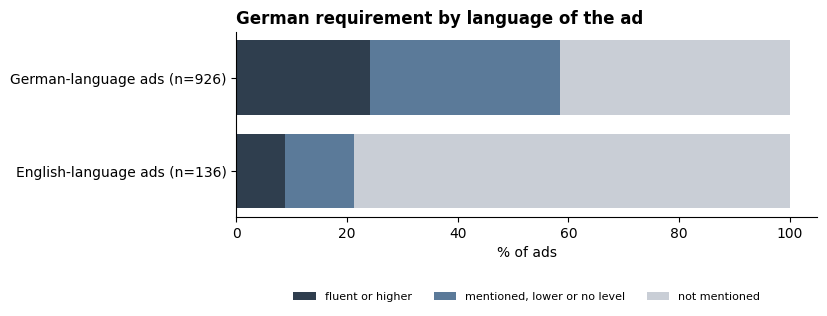

In [12]:
lang = jobs["ad_language"]
eng = lang == "English"
GROUPS = ["fluent or higher", "mentioned, lower or no level", "not mentioned"]
german_group = pd.Series(np.select([jobs["german"].isin(HIGH_GERMAN), jobs["german"] == "not mentioned"],
                                   [GROUPS[0], GROUPS[2]], GROUPS[1]), index=jobs.index, name="German requirement")

print(pd.crosstab(lang, german_group, margins=True)[GROUPS + ["All"]].to_string(), "\n")
by_lang = pd.crosstab(lang, german_group, normalize="index")[GROUPS]
print((by_lang * 100).round(1).to_string(), "\n")

share, low, high = share_ci(eng)
print(f"English-language ads: {eng.sum()} of {N} ({share:.1%}, CI {low:.1%}–{high:.1%})")
share, low, high = share_ci(german_group[eng] == "not mentioned")
print(f"  of these, German not mentioned: {share:.1%} (CI {low:.1%}–{high:.1%})")
print(f"  of these, also newcomer-friendly: {(eng & newcomer).sum()}")
print(f"ads that accept willingness to learn German: {jobs['german_learnable'].sum()}")

t = by_lang.reindex([l for l in ["German", "English"] if l in by_lang.index]) * 100
fig, ax = plt.subplots(figsize=(7.5, 2.4))
left = np.zeros(len(t))
labels = [f"{l}-language ads (n={(lang == l).sum()})" for l in t.index]
for g, color in zip(GROUPS, [DARK, MAIN, GREY]):
    ax.barh(labels, t[g], left=left, color=color, label=g)
    left += t[g].values
ax.invert_yaxis()
ax.set_xlabel("% of ads")
ax.set_title("German requirement by language of the ad")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35), fontsize=8)
save(fig, "german_by_language.png")
plt.show()

In [13]:
# Which roles advertise in English? Share of English-language ads per role
eng_by_role = pd.DataFrame({r: share_ci(eng[jobs["role"] == r]) for r in ROLE_ORDER + ["Other data role"]},
                           index=["share", "low", "high"]).T.sort_values("share", ascending=False)
print((eng_by_role * 100).round(1).to_string())

                  share   low  high
ML / AI Engineer   18.5  13.8  24.3
Other data role    17.6  11.0  27.1
Data Analyst       15.8  11.8  20.9
Data Scientist     11.8   7.1  18.8
Data Engineer       8.9   6.1  12.8
BI / Analytics      3.4   1.3   8.3


## 8. Robustness checks

Do the results depend on decisions made during cleaning? Three variants are compared with the main analysis, in which every ad counts once:
- **Weighted by copies:** each ad counts as often as it was posted (`n_copies` from `02_cleaning`).
- **Without old ads:** ads first published more than a year before the collection are left out. `02_cleaning` kept them and stored their age for this check.
- **Employers weighted equally:** each employer gets the same total weight, so an employer with many ads cannot dominate. This also addresses a limitation of the confidence intervals, which treat every ad as independent.

For each variant, the table compares the skill shares (rank correlation, largest change, same top 15) and the share of newcomer-friendly ads.

In [14]:
old = jobs["age_days"] > 365
employer = jobs["firma"].where(jobs["firma"].notna(), "ad_" + jobs.index.astype(str))   # missing employer = own group
ads_per_employer = employer.value_counts()

print(f"ads older than one year: {old.sum()}")
print(f"employers: {len(ads_per_employer)}, with only one ad: {(ads_per_employer == 1).sum()}, "
      f"most ads from one employer: {ads_per_employer.iloc[0]}\n")

VARIANTS = {"weighted by copies": jobs["n_copies"].fillna(1),
            "without ads older than 1 year": (~old).astype(float),
            "employers weighted equally": 1 / employer.map(ads_per_employer)}

unweighted = S.mean()
rows = []
for name, wt in VARIANTS.items():
    sh = S.mul(wt, axis=0).sum() / wt.sum()
    diff = (sh - unweighted).abs() * 100
    rows.append({"variant": name,
                 "Spearman": round(spearmanr(unweighted, sh).statistic, 3),
                 "largest change (pp)": round(diff.max(), 1),
                 "skill": diff.idxmax(),
                 "same top 15": set(sh.sort_values(ascending=False).index[:15]) == set(TOP),
                 "newcomer-friendly (%)": round((newcomer * wt).sum() / wt.sum() * 100, 1)})
robust = pd.DataFrame(rows).set_index("variant")
print(f"main analysis: newcomer-friendly {newcomer.mean() * 100:.1f}%\n")
print(robust.to_string())

ads older than one year: 38
employers: 639, with only one ad: 460, most ads from one employer: 24

main analysis: newcomer-friendly 21.3%

                               Spearman  largest change (pp)           skill  same top 15  newcomer-friendly (%)
variant                                                                                                         
weighted by copies                0.999                  0.4        Power BI         True                   21.1
without ads older than 1 year     0.998                  0.6  Data modelling         True                   21.1
employers weighted equally        0.985                  4.1          Python        False                   21.4


## 9. Export for the app

The app only uses **aggregated** tables, so no ad text leaves the project:
- `role_skills.csv`: per role and skill, the share of ads that mention the skill, list it as required or only as nice-to-have
- `role_barriers.csv`: per role, the number of ads and the shares for experience, degree, German, English-language ads and newcomer-friendliness

In [15]:
rows = []
for role, g in jobs.groupby("role"):
    for s in SKILLS:
        rows.append({"role": role, "skill": s, "n_ads": len(g),
                     "share_mentioned": g[f"skill_{s}"].mean(),
                     "share_required": g[f"req_{s}"].mean(),
                     "share_nice": g[f"nice_{s}"].mean()})
role_skills = pd.DataFrame(rows)

role_barriers = pd.DataFrame({
    "n_ads": jobs.groupby("role").size(),
    "newcomer_friendly": newcomer.groupby(jobs["role"]).mean(),
    "junior_title": (jobs["seniority"] == "junior").groupby(jobs["role"]).mean(),
    "years_3_plus": MEASURES["3+ or several years required"].groupby(jobs["role"]).mean(),
    "degree": jobs["degree"].groupby(jobs["role"]).mean(),
    "alt_path": jobs["alt_path"].groupby(jobs["role"]).mean(),
    "german_fluent": MEASURES["German: fluent or higher"].groupby(jobs["role"]).mean(),
    "german_not_mentioned": no_german.groupby(jobs["role"]).mean(),
    "english_ad": eng.groupby(jobs["role"]).mean(),
}).round(3)

role_skills.round(3).to_csv(APP_DIR / "role_skills.csv", index=False)
role_barriers.to_csv(APP_DIR / "role_barriers.csv")
print(role_skills.shape, role_barriers.shape)
print(role_barriers.to_string())

(276, 6) (6, 9)
                  n_ads  newcomer_friendly  junior_title  years_3_plus  degree  alt_path  german_fluent  german_not_mentioned  english_ad
role                                                                                                                                     
BI / Analytics      119              0.151         0.042         0.403   0.731     0.387          0.227                 0.445       0.034
Data Analyst        247              0.308         0.101         0.300   0.846     0.340          0.219                 0.510       0.158
Data Engineer       281              0.189         0.025         0.459   0.730     0.359          0.242                 0.388       0.089
Data Scientist      119              0.202         0.059         0.328   0.882     0.151          0.210                 0.420       0.118
ML / AI Engineer    211              0.175         0.038         0.346   0.744     0.308          0.251                 0.460       0.185
Other data role   

## 10. Summary

*To be written from the outputs above.*

**Limitations of this analysis**
- A degree counts when it is *mentioned*; "idealerweise ein Studium" also counts. The hedge logic from `03_extraction` is not yet applied to degrees.
- The heatmap colours describe differences between roles; they are not significance tests.